# Sionna RT Moving-Receiver Channel Study

This notebook studies a **static transmitter and moving receiver** in the exported `test_scene` environment. It computes a static coverage map, retraces propagation paths along a receiver trajectory, extracts path-level and snapshot-level channel data, saves reproducible datasets and documentation, and provides static, interactive, and optional animated visualizations.

The default `balanced` profile is intended for an exploratory run. Use `quick` to validate the workflow and `publication` for higher-fidelity results. The receiver follows a road-aware waypoint route designed to produce repeated LoS/NLoS transitions around the transmitter. Material parameters and geometry determine physical accuracy; illustrative assumptions are never silently inserted.

In [1]:
from __future__ import annotations

import csv
import json
import math
import platform
import sys
from datetime import datetime
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

import sionna
from sionna.rt import (
    Camera, InteractionType, PathSolver, PlanarArray, RadioMapSolver,
    Receiver, Transmitter, load_scene,
)

C0 = 299_792_458.0
EPS = np.finfo(np.float64).tiny

print(f"Python: {sys.version.split()[0]}")
print(f"Sionna: {getattr(sionna, '__version__', 'unknown')}")
print(f"Platform: {platform.platform()}")

Python: 3.13.0
Sionna: 2.1.0
Platform: Windows-10-10.0.19045-SP0


## 1. Study configuration

Edit this cell first. `RX_WAYPOINTS_M` defines a mesh-checked route along the visible roads. It approaches the transmitter, explores northern and southern/western side roads behind building corners, and reconnects to the main road to create repeated LoS/NLoS transitions. Transmit power is set explicitly because it controls RSS while path gain remains dimensionless.

In [2]:
RUN_PROFILE = "balanced"  # "quick", "balanced", or "publication"

PROFILES = {
    "quick":       dict(num_steps=21,  max_depth=2, path_samples=20_000,    rm_samples=100_000,   rm_cell_m=5.0),
    "balanced":    dict(num_steps=61,  max_depth=3, path_samples=100_000,   rm_samples=250_000,   rm_cell_m=4.0),
    "publication": dict(num_steps=181, max_depth=5, path_samples=1_000_000, rm_samples=1_000_000, rm_cell_m=2.0),
}
PROFILE = PROFILES[RUN_PROFILE]

SCENE_PATH = Path("test_scene/test_scene.xml")
OUTPUT_ROOT = Path("outputs")
RUN_NAME = f"mobility_{datetime.now():%Y%m%d_%H%M%S}"
OUTPUT_DIR = OUTPUT_ROOT / RUN_NAME
FIGURE_DIR = OUTPUT_DIR / "figures"
FRAME_DIR = OUTPUT_DIR / "scene_frames"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

# RF and device configuration
CARRIER_FREQUENCY_HZ = 3.5e9
BANDWIDTH_HZ = 20e6
TX_POWER_DBM = 44.0
TX_POSITION_M = np.array([-107.0, 43.0, 10.0])
TX_ORIENTATION_RAD = np.array([0.0, 0.0, 0.0])
# Road-aware route: main road -> northern side road -> southern/western loop -> main road.
# These segments were checked against the exported building footprints with a clearance margin.
RX_WAYPOINTS_M = np.array([
    [ 160.0, -74.0, 2.0], [ 120.0, -56.0, 2.0], [  80.0, -39.0, 2.0],
    [  40.0, -22.0, 2.0], [   0.0,  -4.0, 2.0], [ -40.0,  13.0, 2.0],
    [ -70.0,  28.0, 2.0], [ -82.0,  55.0, 2.0], [-120.0,  68.0, 2.0],
    [ -82.0,  55.0, 2.0], [ -70.0,  28.0, 2.0], [ -40.0,  13.0, 2.0],
    [ -25.0,   5.0, 2.0], [ -25.0, -40.0, 2.0], [ -95.0, -40.0, 2.0],
    [-130.0, -35.0, 2.0], [-155.0, -20.0, 2.0], [-160.0,  20.0, 2.0],
    [-155.0, -20.0, 2.0], [-130.0, -35.0, 2.0], [ -95.0, -40.0, 2.0],
    [ -25.0, -40.0, 2.0], [ -25.0,   5.0, 2.0], [ -40.0,  13.0, 2.0],
    [ -70.0,  28.0, 2.0], [ -40.0,  13.0, 2.0], [   0.0,  -4.0, 2.0],
    [  40.0, -22.0, 2.0], [  80.0, -39.0, 2.0], [ 120.0, -56.0, 2.0],
    [ 160.0, -74.0, 2.0],
])
RX_START_M = RX_WAYPOINTS_M[0].copy()
RX_END_M = RX_WAYPOINTS_M[-1].copy()
RX_SPEED_MPS = 10.0

# Propagation mechanisms
ENABLE_LOS = True
ENABLE_SPECULAR = True
ENABLE_REFRACTION = True
ENABLE_DIFFRACTION = True
ENABLE_EDGE_DIFFRACTION = True
ENABLE_DIFFUSE = True  # Contributions are zero when material scattering coefficients are zero.
DIFFRACTION_LIT_REGION = True
SYNTHETIC_ARRAY = True
DETERMINISTIC = True
SEED = 42

# Static radio map
COMPUTE_RADIO_MAP = True
RADIO_MAP_CENTER_M = [0.0, 0.0, 1.5]
RADIO_MAP_SIZE_M = [400.0, 400.0]
RADIO_MAP_ORIENTATION_RAD = [0.0, 0.0, 0.0]

# Visualization controls
SELECTED_STEP = -1
OPEN_INTERACTIVE_PREVIEW = True
CREATE_SCENE_GIF = True  # Transparent radio-map 3D animation; set False for faster iteration.
SCENE_GIF_FRAME_STRIDE = 2
SCENE_RENDER_RESOLUTION = [960, 600]
SCENE_RENDER_SAMPLES = 16
RADIO_MAP_ALPHA = 0.45  # 0 hides the map; 1 makes it fully opaque.
ANIMATION_FRAME_DURATION_MS = 1000
ANIMATION_CAMERA_POSITION_M = [360.0, -280.0, 180.0]
ANIMATION_CAMERA_LOOK_AT_M = [-10.0, 0.0, 5.0]

print("Profile:", RUN_PROFILE, PROFILE)
print("Outputs:", OUTPUT_DIR.resolve())

Profile: balanced {'num_steps': 61, 'max_depth': 3, 'path_samples': 100000, 'rm_samples': 250000, 'rm_cell_m': 4.0}
Outputs: C:\Users\DHC\Desktop\siona_rt\outputs\mobility_20261104_235027


## 2. Load and audit the scene

The audit is saved in the run metadata. Diffuse scattering requires nonzero material scattering coefficients. This notebook reports zero coefficients rather than inventing uncalibrated values.

In [3]:
if not SCENE_PATH.exists():
    raise FileNotFoundError(f"Scene not found: {SCENE_PATH.resolve()}")

scene = load_scene(str(SCENE_PATH), merge_shapes=False)
scene.frequency = CARRIER_FREQUENCY_HZ
scene.bandwidth = BANDWIDTH_HZ

scene.tx_array = PlanarArray(
    num_rows=4, num_cols=4, vertical_spacing=0.5, horizontal_spacing=0.5,
    pattern="tr38901", polarization="V",
)
scene.rx_array = PlanarArray(
    num_rows=1, num_cols=1, vertical_spacing=0.5, horizontal_spacing=0.5,
    pattern="iso", polarization="V",
)

tx = Transmitter(
    name="tx", position=TX_POSITION_M, orientation=TX_ORIENTATION_RAD,
    power_dbm=TX_POWER_DBM, display_radius=2.0,
)
rx = Receiver(name="rx", position=RX_START_M, display_radius=2.0)
scene.add(tx)
scene.add(rx)

material_audit = []
object_id_lookup = {}
for obj in scene.objects.values():
    mat = obj.radio_material
    object_id_lookup[int(obj.object_id)] = {"object_name": obj.name, "material_name": mat.name}
    record = {
        "object_name": obj.name,
        "object_id": int(obj.object_id),
        "material_name": mat.name,
        "relative_permittivity": float(np.asarray(mat.relative_permittivity).reshape(-1)[0]),
        "conductivity_s_per_m": float(np.asarray(mat.conductivity).reshape(-1)[0]),
        "thickness_m": float(np.asarray(mat.thickness).reshape(-1)[0]),
        "scattering_coefficient": float(np.asarray(mat.scattering_coefficient).reshape(-1)[0]),
        "xpd_coefficient": float(np.asarray(mat.xpd_coefficient).reshape(-1)[0]),
    }
    material_audit.append(record)
    print(record)

if ENABLE_DIFFUSE and not any(m["scattering_coefficient"] > 0 for m in material_audit):
    print("WARNING: Diffuse reflection is enabled, but every material has scattering_coefficient=0.")
    print("Diffuse paths will therefore carry no useful power until calibrated coefficients are assigned.")

{'object_name': 'elm__4', 'object_id': 1, 'material_name': 'itu_marble', 'relative_permittivity': 7.073999881744385, 'conductivity_s_per_m': 0.01755005680024624, 'thickness_m': 0.10000000149011612, 'scattering_coefficient': 0.0, 'xpd_coefficient': 0.0}
{'object_name': 'elm__5', 'object_id': 2, 'material_name': 'itu_metal', 'relative_permittivity': 1.0, 'conductivity_s_per_m': 10000000.0, 'thickness_m': 0.10000000149011612, 'scattering_coefficient': 0.0, 'xpd_coefficient': 0.0}
{'object_name': 'elm__7', 'object_id': 3, 'material_name': 'itu_concrete', 'relative_permittivity': 5.239999771118164, 'conductivity_s_per_m': 0.12308694422245026, 'thickness_m': 0.10000000149011612, 'scattering_coefficient': 0.0, 'xpd_coefficient': 0.0}
Diffuse paths will therefore carry no useful power until calibrated coefficients are assigned.




## 3. Receiver kinematics

The configured road waypoints are resampled at uniform distance so the receiver maintains constant nominal speed even though the route turns and doubles back. The deliberate branches around the transmitter expose building-corner blockage, path birth/death, and reconnection. For a measured route, replace `RX_WAYPOINTS_M` with local-coordinate samples. Orientation is aligned with the direction of travel.

In [4]:
num_steps = PROFILE["num_steps"]
waypoint_segment_lengths_m = np.linalg.norm(np.diff(RX_WAYPOINTS_M, axis=0), axis=1)
waypoint_distance_m = np.concatenate([[0.0], np.cumsum(waypoint_segment_lengths_m)])
distance_m = np.linspace(0.0, waypoint_distance_m[-1], num_steps)
trajectory_m = np.empty((num_steps, 3), dtype=np.float64)
for coordinate in range(3):
    trajectory_m[:, coordinate] = np.interp(distance_m, waypoint_distance_m, RX_WAYPOINTS_M[:, coordinate])
segment_lengths_m = np.linalg.norm(np.diff(trajectory_m, axis=0), axis=1)
time_s = distance_m / RX_SPEED_MPS

velocity_mps = np.zeros_like(trajectory_m)
if num_steps > 1:
    dt = np.diff(time_s)
    segment_velocity = np.diff(trajectory_m, axis=0) / dt[:, None]
    velocity_mps[:-1] = segment_velocity
    velocity_mps[-1] = segment_velocity[-1]

acceleration_mps2 = np.zeros_like(trajectory_m)
if num_steps > 2:
    acceleration_mps2[1:] = np.diff(velocity_mps, axis=0) / np.diff(time_s)[:, None]

orientation_rad = np.zeros_like(trajectory_m)
orientation_rad[:, 0] = np.arctan2(velocity_mps[:, 1], velocity_mps[:, 0])

print(f"Road-route length: {distance_m[-1]:.2f} m through {len(RX_WAYPOINTS_M)} waypoints")
print(f"Duration: {time_s[-1]:.2f} s at {RX_SPEED_MPS:.2f} m/s")
print(f"Snapshots: {num_steps}")

Road-route length: 1183.45 m through 31 waypoints
Duration: 118.35 s at 10.00 m/s
Snapshots: 61


## 4. Static coverage map

Because the transmitter and environment are static, the radio map is computed once and reused while the receiver moves. Recompute it only if the transmitter, environment, receiver antenna orientation used by the map, or material configuration changes.

In [5]:
radio_map = None
if COMPUTE_RADIO_MAP:
    print("Computing the static radio map...")
    radio_map = RadioMapSolver()(
        scene=scene,
        max_depth=PROFILE["max_depth"],
        samples_per_tx=PROFILE["rm_samples"],
        cell_size=[PROFILE["rm_cell_m"], PROFILE["rm_cell_m"]],
        center=RADIO_MAP_CENTER_M,
        size=RADIO_MAP_SIZE_M,
        orientation=RADIO_MAP_ORIENTATION_RAD,
        los=ENABLE_LOS,
        specular_reflection=ENABLE_SPECULAR,
        diffuse_reflection=ENABLE_DIFFUSE,
        refraction=ENABLE_REFRACTION,
        diffraction=ENABLE_DIFFRACTION,
        edge_diffraction=ENABLE_EDGE_DIFFRACTION,
        diffraction_lit_region=DIFFRACTION_LIT_REGION,
        seed=SEED,
    )
    print("Radio-map shape:", radio_map.path_gain.shape)
else:
    print("Radio-map computation skipped.")

Computing the static radio map...


Radio-map shape: (1, 100, 100)


## 5. Extraction helpers and definitions

Array-combined coefficients use equal-power, equal-phase transmit weights `1/sqrt(Ntx)`. Per-path power is based on `|a|²`. Total narrowband power is computed coherently from `|sum(a)|²`; the notebook also records the non-coherent sum for comparison. A mixed path contains more than one interaction type.

In [6]:
INTERACTION_NAMES = {
    int(InteractionType.NONE): "none",
    int(InteractionType.SPECULAR): "specular",
    int(InteractionType.DIFFUSE): "diffuse",
    int(InteractionType.REFRACTION): "refraction",
    int(InteractionType.DIFFRACTION): "diffraction",
}
INVALID_ID = int(np.iinfo(np.uint32).max)
CATEGORIES = ["los", "specular", "refraction", "diffraction", "diffuse", "mixed"]

def db10(x):
    return 10.0 * np.log10(np.maximum(np.asarray(x, dtype=np.float64), EPS))

def watt_to_dbm(x):
    return db10(x) + 30.0

def classify_path(interaction_codes):
    labels = [INTERACTION_NAMES.get(int(code), f"unknown_{int(code)}")
              for code in interaction_codes if int(code) != int(InteractionType.NONE)]
    if not labels:
        return "los", ["los"]
    unique = set(labels)
    return (labels[0] if len(unique) == 1 else "mixed"), labels

def geometric_path_length(tx_pos, rx_pos, vertices, interaction_codes):
    points = [np.asarray(tx_pos, dtype=float)]
    for vertex, code in zip(vertices, interaction_codes):
        if int(code) != int(InteractionType.NONE) and np.all(np.isfinite(vertex)):
            points.append(np.asarray(vertex, dtype=float))
    points.append(np.asarray(rx_pos, dtype=float))
    return float(sum(np.linalg.norm(b - a) for a, b in zip(points[:-1], points[1:])))

def weighted_spread(values, weights):
    values = np.asarray(values, dtype=float)
    weights = np.asarray(weights, dtype=float)
    total = weights.sum()
    if total <= 0 or values.size == 0:
        return float("nan"), float("nan")
    mean = float(np.sum(values * weights) / total)
    rms = float(np.sqrt(np.sum(weights * (values - mean) ** 2) / total))
    return mean, rms

## 6. Retrace paths along the trajectory

This is the main computation. Geometry is recomputed at every snapshot so path birth/death, blockage, and changing interaction points are captured. Doppler is calculated from the assigned receiver velocity. The same random seed is used at every position to reduce Monte-Carlo variation between adjacent snapshots.

In [7]:
path_solver = PathSolver(deterministic=DETERMINISTIC)
tx_power_w = 10.0 ** ((TX_POWER_DBM - 30.0) / 10.0)
noise_power_w = float(np.asarray(scene.thermal_noise_power).reshape(-1)[0])

path_rows = []
summary_rows = []
snapshots = []

for step in range(num_steps):
    rx.position = trajectory_m[step]
    rx.velocity = velocity_mps[step]
    rx.orientation = orientation_rad[step]

    paths = path_solver(
        scene=scene,
        max_depth=PROFILE["max_depth"],
        samples_per_src=PROFILE["path_samples"],
        synthetic_array=SYNTHETIC_ARRAY,
        los=ENABLE_LOS,
        specular_reflection=ENABLE_SPECULAR,
        diffuse_reflection=ENABLE_DIFFUSE,
        refraction=ENABLE_REFRACTION,
        diffraction=ENABLE_DIFFRACTION,
        edge_diffraction=ENABLE_EDGE_DIFFRACTION,
        diffraction_lit_region=DIFFRACTION_LIT_REGION,
        seed=SEED,
    )

    a, tau = paths.cir(normalize_delays=False, out_type="numpy")
    # One RX antenna and one TX device: [tx_ant, path].
    a_by_tx_ant = np.asarray(a[0, 0, 0, :, :, 0], dtype=np.complex64)
    num_tx_ant = a_by_tx_ant.shape[0]
    tx_weights = np.ones(num_tx_ant, dtype=np.complex64) / np.sqrt(num_tx_ant)
    h_path = np.einsum("a,ap->p", tx_weights, a_by_tx_ant)

    tau_s = np.asarray(tau[0, 0], dtype=np.float64)
    valid = np.asarray(paths.valid.numpy()[0, 0], dtype=bool)
    interactions = np.asarray(paths.interactions.numpy()[:, 0, 0, :], dtype=np.uint32)
    object_ids = np.asarray(paths.objects.numpy()[:, 0, 0, :], dtype=np.uint32)
    primitive_ids = np.asarray(paths.primitives.numpy()[:, 0, 0, :], dtype=np.uint32)
    vertices = np.asarray(paths.vertices.numpy()[:, 0, 0, :, :], dtype=np.float64)
    doppler_hz = np.asarray(paths.doppler.numpy()[0, 0], dtype=np.float64)
    theta_t = np.asarray(paths.theta_t.numpy()[0, 0], dtype=np.float64)
    phi_t = np.asarray(paths.phi_t.numpy()[0, 0], dtype=np.float64)
    theta_r = np.asarray(paths.theta_r.numpy()[0, 0], dtype=np.float64)
    phi_r = np.asarray(paths.phi_r.numpy()[0, 0], dtype=np.float64)

    valid_indices = np.flatnonzero(valid)
    category_for_path = {}
    for path_index in valid_indices:
        category, interaction_labels = classify_path(interactions[:, path_index])
        category_for_path[int(path_index)] = category
        gain_linear = float(np.abs(h_path[path_index]) ** 2)
        object_names, material_names, used_vertices, used_primitives = [], [], [], []
        for depth, code in enumerate(interactions[:, path_index]):
            if int(code) == int(InteractionType.NONE):
                continue
            oid = int(object_ids[depth, path_index])
            info = object_id_lookup.get(oid, {"object_name": "unknown", "material_name": "unknown"})
            object_names.append(info["object_name"])
            material_names.append(info["material_name"])
            used_primitives.append(int(primitive_ids[depth, path_index]))
            used_vertices.append([float(x) for x in vertices[depth, path_index]])

        path_rows.append({
            "step": step, "time_s": float(time_s[step]), "distance_along_route_m": float(distance_m[step]),
            "rx_x_m": float(trajectory_m[step, 0]), "rx_y_m": float(trajectory_m[step, 1]), "rx_z_m": float(trajectory_m[step, 2]),
            "rx_vx_mps": float(velocity_mps[step, 0]), "rx_vy_mps": float(velocity_mps[step, 1]), "rx_vz_mps": float(velocity_mps[step, 2]),
            "path_index": int(path_index), "category": category,
            "interaction_sequence": " > ".join(interaction_labels),
            "object_sequence": " > ".join(object_names), "material_sequence": " > ".join(material_names),
            "primitive_ids_json": json.dumps(used_primitives), "vertices_json": json.dumps(used_vertices),
            "delay_s": float(tau_s[path_index]), "delay_ns": float(tau_s[path_index] * 1e9),
            "delay_distance_m": float(tau_s[path_index] * C0),
            "geometric_length_m": geometric_path_length(TX_POSITION_M, trajectory_m[step], vertices[:, path_index], interactions[:, path_index]),
            "doppler_hz": float(doppler_hz[path_index]),
            "a_real": float(h_path[path_index].real), "a_imag": float(h_path[path_index].imag),
            "amplitude": float(np.abs(h_path[path_index])), "phase_rad": float(np.angle(h_path[path_index])),
            "path_gain_linear": gain_linear, "path_gain_db": float(db10(gain_linear)),
            "path_loss_db": float(-db10(gain_linear)),
            "received_power_w": float(tx_power_w * gain_linear),
            "received_power_dbm": float(TX_POWER_DBM + db10(gain_linear)),
            "aod_zenith_deg": float(np.degrees(theta_t[path_index])), "aod_azimuth_deg": float(np.degrees(phi_t[path_index])),
            "aoa_zenith_deg": float(np.degrees(theta_r[path_index])), "aoa_azimuth_deg": float(np.degrees(phi_r[path_index])),
        })

    hv = h_path[valid]
    tv = tau_s[valid]
    dv = doppler_hz[valid]
    powers = np.abs(hv) ** 2
    h_total = np.sum(hv) if hv.size else 0j
    coherent_gain = float(np.abs(h_total) ** 2)
    incoherent_gain = float(np.sum(powers))
    mean_delay_s, rms_delay_s = weighted_spread(tv, powers)
    mean_doppler_hz, rms_doppler_hz = weighted_spread(dv, powers)

    summary = {
        "step": step, "time_s": float(time_s[step]), "distance_along_route_m": float(distance_m[step]),
        "rx_x_m": float(trajectory_m[step, 0]), "rx_y_m": float(trajectory_m[step, 1]), "rx_z_m": float(trajectory_m[step, 2]),
        "speed_mps": float(np.linalg.norm(velocity_mps[step])), "acceleration_mps2": float(np.linalg.norm(acceleration_mps2[step])),
        "num_paths": int(valid.sum()), "is_outage": bool(valid.sum() == 0),
        "has_los": any(category_for_path.get(int(i)) == "los" for i in valid_indices),
        "coherent_path_gain_linear": coherent_gain, "coherent_path_gain_db": float(db10(coherent_gain)),
        "path_loss_db": float(-db10(coherent_gain)),
        "rss_w": float(tx_power_w * coherent_gain), "rss_dbm": float(TX_POWER_DBM + db10(coherent_gain)),
        "incoherent_rss_w": float(tx_power_w * incoherent_gain), "incoherent_rss_dbm": float(TX_POWER_DBM + db10(incoherent_gain)),
        "noise_power_w": noise_power_w, "noise_power_dbm": float(watt_to_dbm(noise_power_w)),
        "snr_linear": float(tx_power_w * coherent_gain / max(noise_power_w, EPS)),
        "snr_db": float(db10(tx_power_w * coherent_gain / max(noise_power_w, EPS))),
        "mean_delay_s": mean_delay_s, "rms_delay_spread_s": rms_delay_s, "rms_delay_spread_ns": rms_delay_s * 1e9,
        "mean_doppler_hz": mean_doppler_hz, "rms_doppler_spread_hz": rms_doppler_hz,
    }
    for category in CATEGORIES:
        indices = [i for i in valid_indices if category_for_path.get(int(i)) == category]
        group_h = np.sum(h_path[indices]) if indices else 0j
        summary[f"{category}_num_paths"] = len(indices)
        summary[f"{category}_power_dbm"] = float(TX_POWER_DBM + db10(np.abs(group_h) ** 2))

    summary_rows.append(summary)
    snapshots.append({
        "paths": paths, "a_by_tx_ant": a_by_tx_ant, "h_path": h_path, "tau_s": tau_s, "valid": valid,
        "interactions": interactions, "object_ids": object_ids, "primitive_ids": primitive_ids,
        "vertices": vertices, "doppler_hz": doppler_hz, "theta_t": theta_t, "phi_t": phi_t,
        "theta_r": theta_r, "phi_r": phi_r, "categories": category_for_path,
    })
    print(f"[{step + 1:>3}/{num_steps}] t={time_s[step]:7.2f} s, paths={valid.sum():4d}, RSS={summary['rss_dbm']:8.2f} dBm")

print("Trajectory simulation complete.")

[  1/61] t=   0.00 s, paths=  67, RSS=  -28.72 dBm
[  2/61] t=   1.97 s, paths=  78, RSS=  -27.99 dBm
[  3/61] t=   3.94 s, paths=  82, RSS=  -30.23 dBm
[  4/61] t=   5.92 s, paths=  91, RSS=  -35.98 dBm
[  5/61] t=   7.89 s, paths=  89, RSS=  -43.42 dBm
[  6/61] t=   9.86 s, paths= 105, RSS=  -24.76 dBm
[  7/61] t=  11.83 s, paths= 111, RSS=  -27.26 dBm
[  8/61] t=  13.81 s, paths= 104, RSS=  -28.40 dBm
[  9/61] t=  15.78 s, paths= 106, RSS=  -25.88 dBm
[ 10/61] t=  17.75 s, paths= 101, RSS=  -22.64 dBm
[ 11/61] t=  19.72 s, paths= 106, RSS=  -27.50 dBm
[ 12/61] t=  21.70 s, paths= 110, RSS=  -38.85 dBm
[ 13/61] t=  23.67 s, paths= 114, RSS=  -26.05 dBm
[ 14/61] t=  25.64 s, paths= 127, RSS=  -21.15 dBm
[ 15/61] t=  27.61 s, paths= 123, RSS=  -19.33 dBm
[ 16/61] t=  29.59 s, paths= 126, RSS=  -35.64 dBm
[ 17/61] t=  31.56 s, paths= 113, RSS=  -66.50 dBm
[ 18/61] t=  33.53 s, paths= 133, RSS=  -50.76 dBm
[ 19/61] t=  35.50 s, paths= 124, RSS=  -39.91 dBm
[ 20/61] t=  37.48 s, paths= 12

## 7. Save reproducible datasets and documentation

The run creates:

- `path_data.csv`: one row per valid propagation path and snapshot
- `snapshot_summary.csv`: one row per receiver position
- `channel_arrays.npz`: padded numerical arrays, including per-antenna complex coefficients
- `run_config.json`: configuration, versions, assumptions, and material audit
- `DATA_DICTIONARY.md`: definitions and units
- `figures/`: documentation-ready plots

In [8]:
def write_csv(path, rows):
    if not rows:
        return
    with path.open("w", newline="", encoding="utf-8") as handle:
        writer = csv.DictWriter(handle, fieldnames=list(rows[0].keys()))
        writer.writeheader()
        writer.writerows(rows)

write_csv(OUTPUT_DIR / "path_data.csv", path_rows)
write_csv(OUTPUT_DIR / "snapshot_summary.csv", summary_rows)

max_paths = max((snap["valid"].size for snap in snapshots), default=0)
max_depth = PROFILE["max_depth"]
num_tx_ant = scene.tx_array.num_ant
shape_sp = (num_steps, max_paths)
packed = {
    "trajectory_m": trajectory_m, "time_s": time_s, "distance_m": distance_m,
    "velocity_mps": velocity_mps, "acceleration_mps2": acceleration_mps2, "orientation_rad": orientation_rad,
    "valid": np.zeros(shape_sp, dtype=bool),
    "tau_s": np.full(shape_sp, np.nan, dtype=np.float32),
    "doppler_hz": np.full(shape_sp, np.nan, dtype=np.float32),
    "h_path": np.full(shape_sp, np.nan + 1j * np.nan, dtype=np.complex64),
    "a_by_tx_ant": np.full((num_steps, num_tx_ant, max_paths), np.nan + 1j * np.nan, dtype=np.complex64),
    "interactions": np.zeros((num_steps, max_depth, max_paths), dtype=np.uint32),
    "object_ids": np.full((num_steps, max_depth, max_paths), INVALID_ID, dtype=np.uint32),
    "primitive_ids": np.full((num_steps, max_depth, max_paths), INVALID_ID, dtype=np.uint32),
    "vertices_m": np.full((num_steps, max_depth, max_paths, 3), np.nan, dtype=np.float32),
    "theta_t_rad": np.full(shape_sp, np.nan, dtype=np.float32), "phi_t_rad": np.full(shape_sp, np.nan, dtype=np.float32),
    "theta_r_rad": np.full(shape_sp, np.nan, dtype=np.float32), "phi_r_rad": np.full(shape_sp, np.nan, dtype=np.float32),
}
for step, snap in enumerate(snapshots):
    n = snap["valid"].size
    packed["valid"][step, :n] = snap["valid"]
    for key in ["tau_s", "doppler_hz", "h_path", "theta_t", "phi_t", "theta_r", "phi_r"]:
        target_key = {"theta_t": "theta_t_rad", "phi_t": "phi_t_rad", "theta_r": "theta_r_rad", "phi_r": "phi_r_rad"}.get(key, key)
        packed[target_key][step, :n] = snap[key]
    packed["a_by_tx_ant"][step, :, :n] = snap["a_by_tx_ant"]
    packed["interactions"][step, :, :n] = snap["interactions"]
    packed["object_ids"][step, :, :n] = snap["object_ids"]
    packed["primitive_ids"][step, :, :n] = snap["primitive_ids"]
    packed["vertices_m"][step, :, :n, :] = snap["vertices"]
np.savez_compressed(OUTPUT_DIR / "channel_arrays.npz", **packed)

config = {
    "run_name": RUN_NAME, "created_local": datetime.now().isoformat(), "run_profile": RUN_PROFILE, "profile": PROFILE,
    "scene_path": str(SCENE_PATH), "carrier_frequency_hz": CARRIER_FREQUENCY_HZ, "bandwidth_hz": BANDWIDTH_HZ,
    "tx_power_dbm": TX_POWER_DBM, "tx_position_m": TX_POSITION_M.tolist(), "rx_start_m": RX_START_M.tolist(),
    "rx_end_m": RX_END_M.tolist(), "rx_waypoints_m": RX_WAYPOINTS_M.tolist(),
    "trajectory_description": "Road-aware out-and-back route with northern and southern/western branches around the transmitter",
    "rx_speed_mps": RX_SPEED_MPS, "synthetic_array": SYNTHETIC_ARRAY,
    "mechanisms": {"los": ENABLE_LOS, "specular": ENABLE_SPECULAR, "refraction": ENABLE_REFRACTION,
                       "diffraction": ENABLE_DIFFRACTION, "edge_diffraction": ENABLE_EDGE_DIFFRACTION,
                       "diffuse": ENABLE_DIFFUSE, "diffraction_lit_region": DIFFRACTION_LIT_REGION},
    "radio_map": {"computed": COMPUTE_RADIO_MAP, "center_m": RADIO_MAP_CENTER_M, "size_m": RADIO_MAP_SIZE_M,
                  "cell_size_m": PROFILE["rm_cell_m"], "samples_per_tx": PROFILE["rm_samples"]},
    "animation": {"created": CREATE_SCENE_GIF, "radio_map_alpha": RADIO_MAP_ALPHA,
                  "frame_stride": SCENE_GIF_FRAME_STRIDE, "frame_duration_ms": ANIMATION_FRAME_DURATION_MS,
                  "camera_position_m": ANIMATION_CAMERA_POSITION_M, "camera_look_at_m": ANIMATION_CAMERA_LOOK_AT_M},
    "array_combining_assumption": "Equal-power, equal-phase TX weights (1/sqrt(num_tx_ant)); one RX antenna.",
    "power_interpretation": "Narrowband coherent power at baseband reference frequency; per-path power uses |a_i|^2.",
    "material_audit": material_audit,
    "versions": {"python": sys.version, "sionna": getattr(sionna, '__version__', 'unknown'), "numpy": np.__version__},
}
(OUTPUT_DIR / "run_config.json").write_text(json.dumps(config, indent=2), encoding="utf-8")

data_dictionary = """# Mobility Channel Study — Data Dictionary

## Files
- `path_data.csv`: one row for each valid path at each trajectory snapshot.
- `snapshot_summary.csv`: aggregate channel and kinematic metrics for each snapshot.
- `channel_arrays.npz`: padded raw numerical tensors. Use the `valid` mask before analysis.
- `run_config.json`: complete run configuration, versions, assumptions, and material audit.

## Important definitions
- `path_gain_linear = |a_i|^2`; `path_gain_db = 10 log10(path_gain_linear)`.
- `path_loss_db = -path_gain_db`.
- `received_power_w = transmit_power_w * path_gain_linear`.
- `rss_w` uses coherent path summation: `Pt * |sum_i a_i|^2`.
- `incoherent_rss_w` uses `Pt * sum_i |a_i|^2` and excludes inter-path interference.
- Delay spread and Doppler spread are power-weighted RMS values.
- `category=mixed` means a path contains more than one propagation-interaction type.
- Vertices, object IDs, primitive IDs, and interactions are indexed by path depth.

## Physical limitations
Results depend on mesh accuracy and radio-material calibration. Refraction uses Sionna RT's thin-slab model. Diffraction is first-order. Diffuse scattering requires nonzero calibrated scattering coefficients. Atmospheric, vegetation, vehicle, and hardware losses are absent unless explicitly modeled.
"""
(OUTPUT_DIR / "DATA_DICTIONARY.md").write_text(data_dictionary, encoding="utf-8")

print(f"Saved {len(path_rows):,} path rows and {len(summary_rows):,} snapshot rows to {OUTPUT_DIR.resolve()}")

Saved 4,826 path rows and 61 snapshot rows to C:\Users\DHC\Desktop\siona_rt\outputs\mobility_20261104_235027


## 8. Coverage, kinematics, power, delay, and Doppler plots

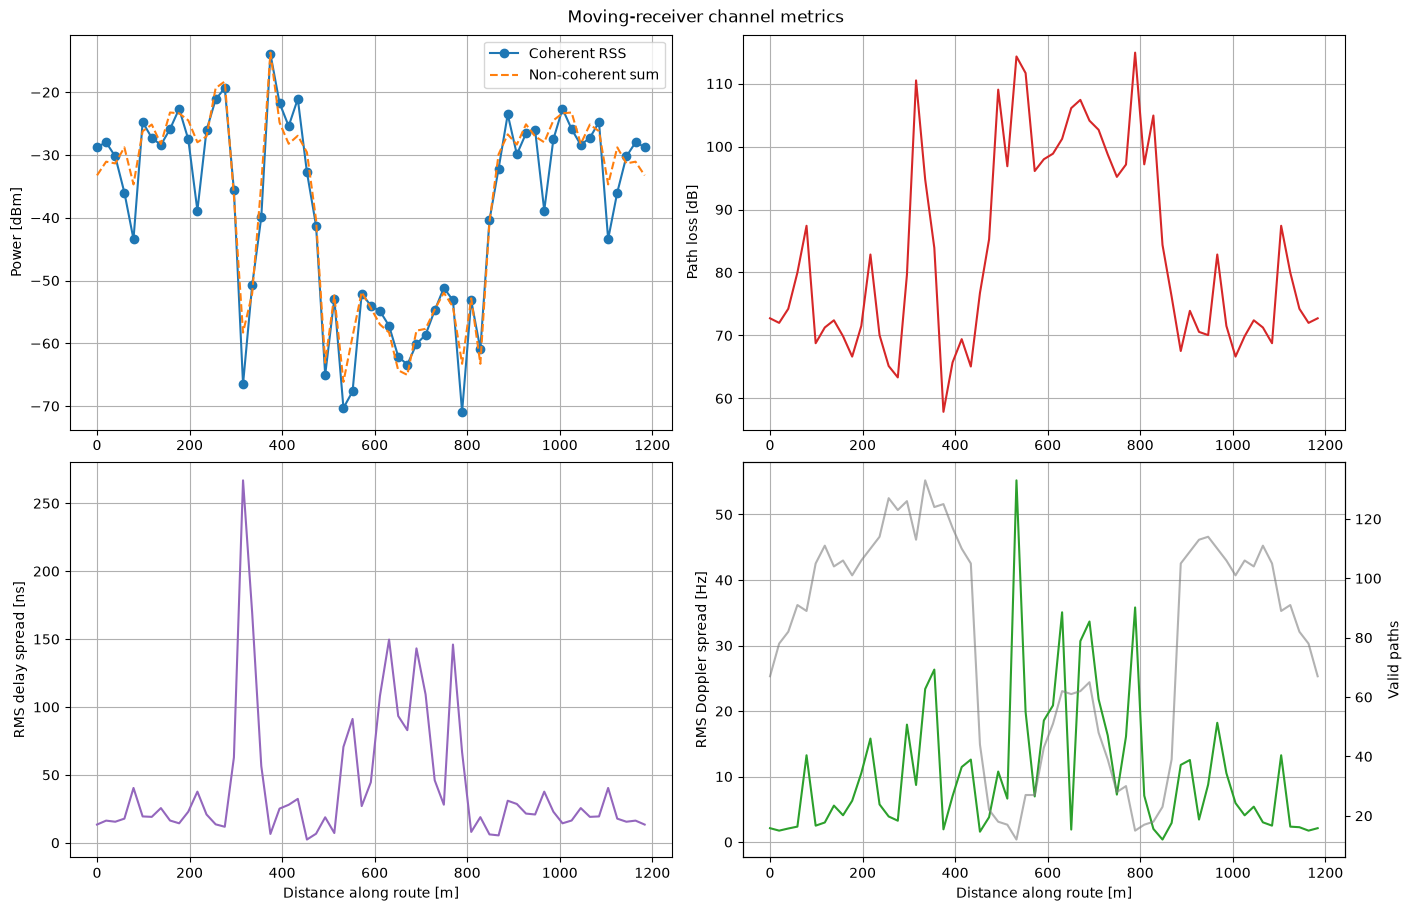

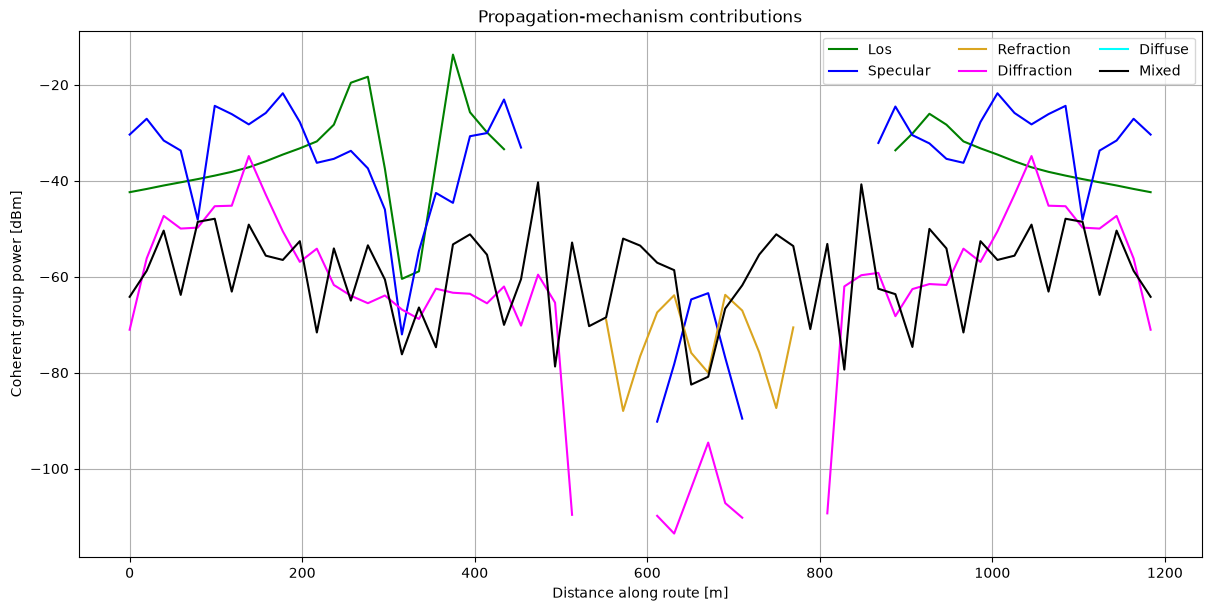

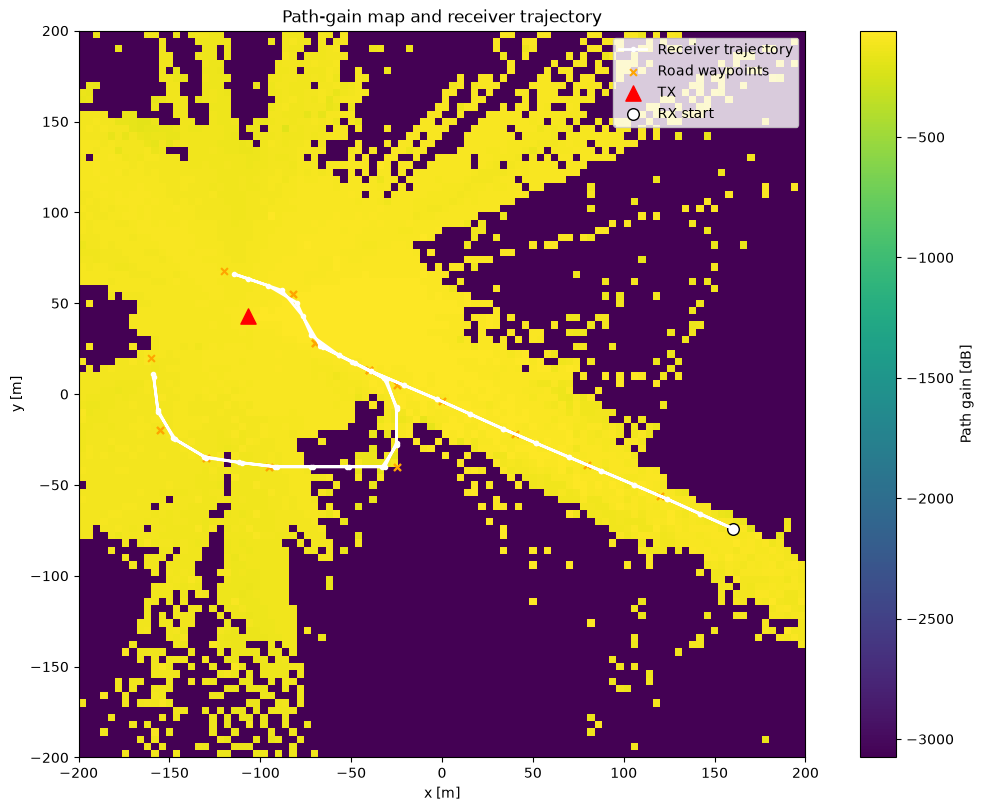

In [9]:
x = np.array([r["distance_along_route_m"] for r in summary_rows])
rss = np.array([r["rss_dbm"] for r in summary_rows])
path_loss = np.array([r["path_loss_db"] for r in summary_rows])
snr = np.array([r["snr_db"] for r in summary_rows])
num_paths_series = np.array([r["num_paths"] for r in summary_rows])
delay_spread_ns = np.array([r["rms_delay_spread_ns"] for r in summary_rows])
doppler_spread_hz = np.array([r["rms_doppler_spread_hz"] for r in summary_rows])

fig, axes = plt.subplots(2, 2, figsize=(14, 9), constrained_layout=True)
rss_for_plot = np.where(num_paths_series > 0, rss, np.nan)
incoherent_for_plot = np.where(num_paths_series > 0, [r["incoherent_rss_dbm"] for r in summary_rows], np.nan)
axes[0, 0].plot(x, rss_for_plot, marker="o", label="Coherent RSS")
axes[0, 0].plot(x, incoherent_for_plot, ls="--", label="Non-coherent sum")
for outage_x in x[num_paths_series == 0]: axes[0, 0].axvline(outage_x, color="red", alpha=0.25, lw=2)
axes[0, 0].set_ylabel("Power [dBm]"); axes[0, 0].legend(); axes[0, 0].grid(True)
axes[0, 1].plot(x, path_loss, color="tab:red"); axes[0, 1].set_ylabel("Path loss [dB]"); axes[0, 1].grid(True)
axes[1, 0].plot(x, delay_spread_ns, color="tab:purple"); axes[1, 0].set_ylabel("RMS delay spread [ns]"); axes[1, 0].grid(True)
axes[1, 1].plot(x, doppler_spread_hz, color="tab:green", label="Doppler spread")
ax2 = axes[1, 1].twinx(); ax2.plot(x, num_paths_series, color="tab:gray", alpha=0.6, label="Paths")
axes[1, 1].set_ylabel("RMS Doppler spread [Hz]"); ax2.set_ylabel("Valid paths"); axes[1, 1].grid(True)
for ax in axes[-1]: ax.set_xlabel("Distance along route [m]")
fig.suptitle("Moving-receiver channel metrics")
fig.savefig(FIGURE_DIR / "channel_metrics.png", dpi=180)
plt.show()

fig, ax = plt.subplots(figsize=(12, 6), constrained_layout=True)
colors = {"los": "green", "specular": "blue", "refraction": "goldenrod",
          "diffraction": "magenta", "diffuse": "cyan", "mixed": "black"}
for category in CATEGORIES:
    group_power = np.array([r[f"{category}_power_dbm"] for r in summary_rows])
    group_count = np.array([r[f"{category}_num_paths"] for r in summary_rows])
    ax.plot(x, np.where(group_count > 0, group_power, np.nan), label=category.title(), color=colors[category])
ax.set_xlabel("Distance along route [m]"); ax.set_ylabel("Coherent group power [dBm]")
ax.set_title("Propagation-mechanism contributions"); ax.grid(True); ax.legend(ncol=3)
fig.savefig(FIGURE_DIR / "mechanism_contributions.png", dpi=180)
plt.show()

if radio_map is not None:
    rm_db = db10(np.asarray(radio_map.path_gain.numpy()[0]))
    cx, cy, _ = RADIO_MAP_CENTER_M; sx, sy = RADIO_MAP_SIZE_M
    extent = [cx - sx / 2, cx + sx / 2, cy - sy / 2, cy + sy / 2]
    fig, ax = plt.subplots(figsize=(10, 8), constrained_layout=True)
    image = ax.imshow(rm_db, origin="lower", extent=extent, cmap="viridis", aspect="equal")
    ax.plot(trajectory_m[:, 0], trajectory_m[:, 1], "w.-", lw=2, label="Receiver trajectory")
    ax.scatter(RX_WAYPOINTS_M[:, 0], RX_WAYPOINTS_M[:, 1], marker="x", s=24, c="orange", label="Road waypoints")
    ax.scatter(*TX_POSITION_M[:2], marker="^", s=120, c="red", label="TX")
    ax.scatter(*trajectory_m[0, :2], marker="o", s=70, c="white", edgecolor="black", label="RX start")
    ax.set_xlabel("x [m]"); ax.set_ylabel("y [m]"); ax.set_title("Path-gain map and receiver trajectory")
    fig.colorbar(image, ax=ax, label="Path gain [dB]"); ax.legend()
    fig.savefig(FIGURE_DIR / "coverage_and_trajectory.png", dpi=180)
    plt.show()

## 9. Inspect one snapshot: 3D path geometry and power-delay profile

This custom view colors paths by interaction category. The following cell also opens Sionna's native interactive 3D viewer with the actual buildings and radio map.

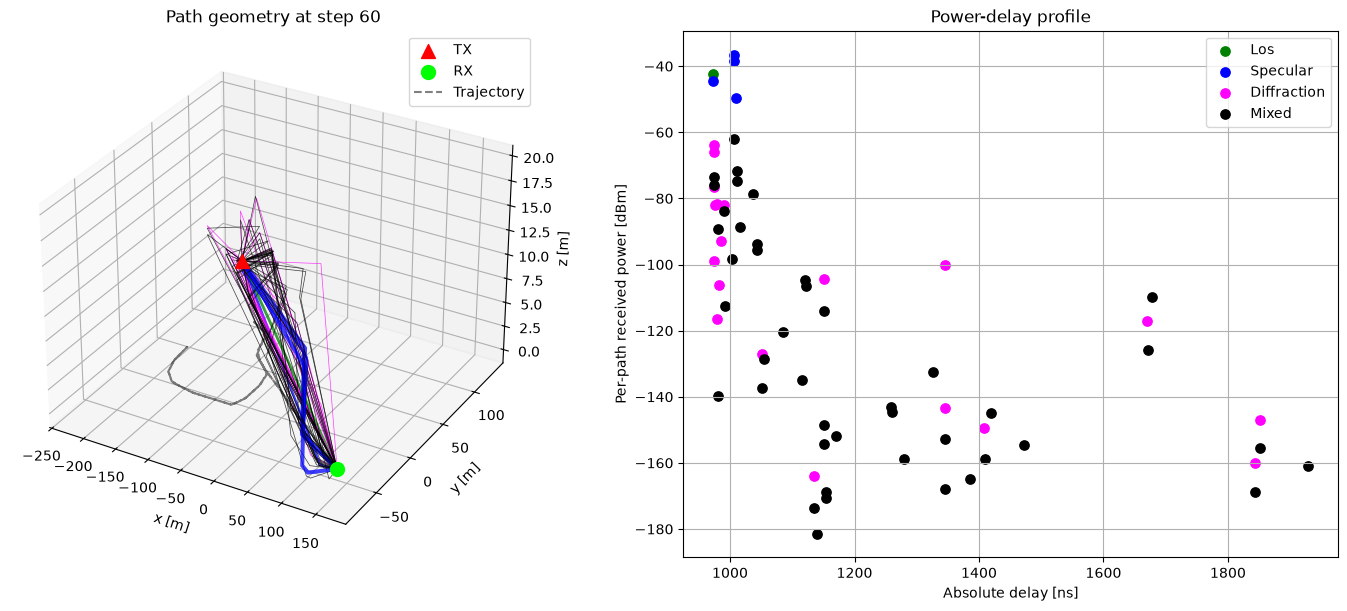

In [10]:
selected_step = SELECTED_STEP % num_steps
snap = snapshots[selected_step]
rx.position = trajectory_m[selected_step]
rx.velocity = velocity_mps[selected_step]
rx.orientation = orientation_rad[selected_step]

fig = plt.figure(figsize=(14, 6), constrained_layout=True)
ax3d = fig.add_subplot(1, 2, 1, projection="3d")
axp = fig.add_subplot(1, 2, 2)
for path_index in np.flatnonzero(snap["valid"]):
    codes = snap["interactions"][:, path_index]
    points = [TX_POSITION_M]
    points += [snap["vertices"][d, path_index] for d, code in enumerate(codes) if int(code) != int(InteractionType.NONE)]
    points += [trajectory_m[selected_step]]
    points = np.asarray(points)
    category = snap["categories"][int(path_index)]
    linewidth = 0.5 + 3.0 * np.abs(snap["h_path"][path_index]) / max(np.max(np.abs(snap["h_path"][snap["valid"]])), EPS)
    ax3d.plot(points[:, 0], points[:, 1], points[:, 2], color=colors[category], alpha=0.75, lw=linewidth)
ax3d.scatter(*TX_POSITION_M, c="red", marker="^", s=100, label="TX")
ax3d.scatter(*trajectory_m[selected_step], c="lime", marker="o", s=100, label="RX")
ax3d.plot(trajectory_m[:, 0], trajectory_m[:, 1], trajectory_m[:, 2], "k--", alpha=0.5, label="Trajectory")
ax3d.set_xlabel("x [m]"); ax3d.set_ylabel("y [m]"); ax3d.set_zlabel("z [m]")
ax3d.set_title(f"Path geometry at step {selected_step}"); ax3d.legend()

valid_idx = np.flatnonzero(snap["valid"])
delays_ns = snap["tau_s"][valid_idx] * 1e9
path_power_dbm = TX_POWER_DBM + db10(np.abs(snap["h_path"][valid_idx]) ** 2)
for category in CATEGORIES:
    mask = np.array([snap["categories"][int(i)] == category for i in valid_idx])
    if np.any(mask):
        axp.scatter(delays_ns[mask], path_power_dbm[mask], label=category.title(), color=colors[category], s=45)
axp.set_xlabel("Absolute delay [ns]"); axp.set_ylabel("Per-path received power [dBm]")
axp.set_title("Power-delay profile"); axp.grid(True); axp.legend()
fig.savefig(FIGURE_DIR / f"snapshot_{selected_step:03d}_paths_and_pdp.png", dpi=180)
plt.show()

if OPEN_INTERACTIVE_PREVIEW:
    preview_kwargs = dict(paths=snap["paths"], show_devices=True, show_orientations=False)
    if radio_map is not None:
        preview_kwargs.update(radio_map=radio_map, rm_metric="path_gain", rm_db_scale=True)
    scene.preview(**preview_kwargs)

## 10. Transparent-radio-map 3D scene animation

This animation shows the actual building scene, a semi-transparent static radio map, the moving receiver, and paths that are retraced at every position. Buildings naturally occlude the radio map and paths, making blockage and NLoS behavior easier to interpret. The frame label reports time, distance, RSS, path count, and LoS/NLoS state.

Sionna renders valid radio-map cells as opaque. To provide real transparency without altering Sionna internals, each frame is rendered twice from the same camera—once without the radio map and once with it—and the images are alpha-composited using `RADIO_MAP_ALPHA`. Set `CREATE_SCENE_GIF=False` for faster iterative runs.

In [11]:
if CREATE_SCENE_GIF:
    from PIL import Image, ImageDraw
    import mitsuba as mi

    FRAME_DIR.mkdir(parents=True, exist_ok=True)
    camera = Camera(position=ANIMATION_CAMERA_POSITION_M, look_at=ANIMATION_CAMERA_LOOK_AT_M)
    frame_paths = []
    frame_steps = list(range(0, num_steps, SCENE_GIF_FRAME_STRIDE))
    if frame_steps[-1] != num_steps - 1:
        frame_steps.append(num_steps - 1)

    # Use fixed map limits across all frames so color always has the same meaning.
    rm_vmin_db = rm_vmax_db = None
    if radio_map is not None:
        rm_linear = np.asarray(radio_map.path_gain.numpy()[0], dtype=float)
        rm_valid = rm_linear[np.logical_and(rm_linear > 0, np.isfinite(rm_linear))]
        if rm_valid.size:
            rm_db = db10(rm_valid)
            rm_vmin_db, rm_vmax_db = np.percentile(rm_db, [5.0, 99.0])

    def bitmap_to_pil(bitmap):
        converted = bitmap.convert(component_format=mi.Struct.Type.UInt8, srgb_gamma=True)
        array = np.asarray(converted)
        if array.ndim == 3 and array.shape[-1] > 3:
            array = array[..., :3]
        return Image.fromarray(np.array(array, copy=True), mode="RGB")

    for frame_number, step in enumerate(frame_steps):
        rx.position = trajectory_m[step]
        rx.velocity = velocity_mps[step]
        rx.orientation = orientation_rad[step]
        frame_path = FRAME_DIR / f"frame_{frame_number:04d}.png"
        common_render_kwargs = dict(
            camera=camera, paths=snapshots[step]["paths"], return_bitmap=True,
            resolution=SCENE_RENDER_RESOLUTION, num_samples=SCENE_RENDER_SAMPLES,
            show_devices=True, show_orientations=False,
        )
        # Base render keeps buildings, receiver, and paths unobstructed.
        base_image = bitmap_to_pil(scene.render(**common_render_kwargs))
        if radio_map is not None and RADIO_MAP_ALPHA > 0:
            map_bitmap = scene.render(
                **common_render_kwargs, radio_map=radio_map, rm_metric="path_gain", rm_db_scale=True,
                rm_vmin=float(rm_vmin_db) if rm_vmin_db is not None else None,
                rm_vmax=float(rm_vmax_db) if rm_vmax_db is not None else None,
            )
            map_image = bitmap_to_pil(map_bitmap)
            frame_image = Image.blend(base_image, map_image, float(np.clip(RADIO_MAP_ALPHA, 0.0, 1.0)))
            map_image.close()
        else:
            frame_image = base_image.copy()

        # Add an analysis label without covering the propagation geometry.
        status = ("OUTAGE" if summary_rows[step]["is_outage"] else
                  ("LoS" if summary_rows[step]["has_los"] else "NLoS"))
        rss_label = "outage" if summary_rows[step]["is_outage"] else f"{summary_rows[step]['rss_dbm']:.1f} dBm"
        label = (f"Step {step}/{num_steps - 1} | t={time_s[step]:.2f} s | "
                 f"d={distance_m[step]:.1f} m | RSS={rss_label} | "
                 f"paths={summary_rows[step]['num_paths']} | {status}")
        draw = ImageDraw.Draw(frame_image, "RGBA")
        text_box = draw.textbbox((0, 0), label)
        box_width = text_box[2] - text_box[0] + 24
        box_height = text_box[3] - text_box[1] + 18
        draw.rounded_rectangle((12, 12, 12 + box_width, 12 + box_height), radius=8, fill=(0, 0, 0, 165))
        draw.text((24, 20), label, fill=(255, 255, 255, 255))
        frame_image.save(frame_path)
        base_image.close()
        frame_image.close()
        frame_paths.append(frame_path)
        print(f"Rendered {frame_number + 1}/{len(frame_steps)}")

    images = [Image.open(path).convert("RGB") for path in frame_paths]
    gif_path = OUTPUT_DIR / "receiver_motion_transparent_radio_map.gif"
    images[0].save(gif_path, save_all=True, append_images=images[1:], duration=ANIMATION_FRAME_DURATION_MS, loop=0)
    for image in images:
        image.close()
    print("Saved transparent-radio-map animation:", gif_path.resolve())
else:
    print("Scene GIF skipped. Set CREATE_SCENE_GIF=True to enable it.")

Rendered 1/31
Rendered 2/31
Rendered 3/31
Rendered 4/31
Rendered 5/31
Rendered 6/31
Rendered 7/31
Rendered 8/31
Rendered 9/31
Rendered 10/31
Rendered 11/31
Rendered 12/31
Rendered 13/31
Rendered 14/31
Rendered 15/31
Rendered 16/31
Rendered 17/31
Rendered 18/31
Rendered 19/31
Rendered 20/31
Rendered 21/31
Rendered 22/31
Rendered 23/31
Rendered 24/31
Rendered 25/31
Rendered 26/31
Rendered 27/31


c:\Users\DHC\Desktop\siona_rt\.venv\Lib\site-packages\drjit\ast.py:838: RuntimeWarning: The AST-transforming decorator @drjit.syntax was called more than 1000 times by your program. Since transforming and recompiling Python code is a relatively expensive operation, it should not be used within loops or subroutines. Please move the function to be transformed to the top program level and decorate it there.
  warnings.warn(


Rendered 28/31
Rendered 29/31
Rendered 30/31
Rendered 31/31
Saved transparent-radio-map animation: C:\Users\DHC\Desktop\siona_rt\outputs\mobility_20261104_235027\receiver_motion_transparent_radio_map.gif


## 11. Run summary

Review the material warning, configuration JSON, and data dictionary before treating results as calibrated predictions. The strongest next accuracy improvement is assigning measured material thickness and diffuse-scattering parameters to the exported geometry.

In [12]:
best_step = int(np.nanargmax(rss))
worst_step = int(np.nanargmin(rss))
report = f"""# Mobility Channel Study — Run Summary

- Run: `{RUN_NAME}`
- Profile: `{RUN_PROFILE}`
- Frequency: {CARRIER_FREQUENCY_HZ / 1e9:.3f} GHz
- Bandwidth: {BANDWIDTH_HZ / 1e6:.3f} MHz
- Transmit power: {TX_POWER_DBM:.2f} dBm
- Trajectory: {distance_m[-1]:.2f} m over {time_s[-1]:.2f} s
- Snapshots: {num_steps}
- Extracted valid paths: {len(path_rows)}
- RSS range: {np.nanmin(rss):.2f} to {np.nanmax(rss):.2f} dBm
- Best step: {best_step} at {distance_m[best_step]:.2f} m
- Worst step: {worst_step} at {distance_m[worst_step]:.2f} m

See `DATA_DICTIONARY.md` and `run_config.json` before reuse.
"""
(OUTPUT_DIR / "RUN_SUMMARY.md").write_text(report, encoding="utf-8")
print(report)
print("All outputs are available at:", OUTPUT_DIR.resolve())

# Mobility Channel Study — Run Summary

- Run: `mobility_20261104_235027`
- Profile: `balanced`
- Frequency: 3.500 GHz
- Bandwidth: 20.000 MHz
- Transmit power: 44.00 dBm
- Trajectory: 1183.45 m over 118.35 s
- Snapshots: 61
- Extracted valid paths: 4826
- RSS range: -70.92 to -13.87 dBm
- Best step: 19 at 374.76 m
- Worst step: 40 at 788.97 m

See `DATA_DICTIONARY.md` and `run_config.json` before reuse.

All outputs are available at: C:\Users\DHC\Desktop\siona_rt\outputs\mobility_20261104_235027
